# A3 demo: seal photo in, sign sequence out

Runs the whole M1 pipeline: find the text row (whole-seal photos only), A1 cuts it into one box per sign in reading order, A2 gives the top-5 templates for each box.

To try your own photo, change `PHOTO` below. Use `read_seal(image)` for a whole seal, `read_text_row(image)` for a photo of just the text row, and add `mirrored=True` if the photo is of the seal itself rather than an impression.

In [1]:
import cv2
import matplotlib.pyplot as plt

from indus.data import REPO_ROOT, template_path
from indus.pipeline import draw_readings, read_text_row
from indus.segment import load_image

PHOTO = REPO_ROOT / "data" / "raw" / "seal_samples_ocr2017" / "text_row_28.png"

## 1. Run the pipeline

sequence (reading order): 51 380 318 40 326 97 397 413 55


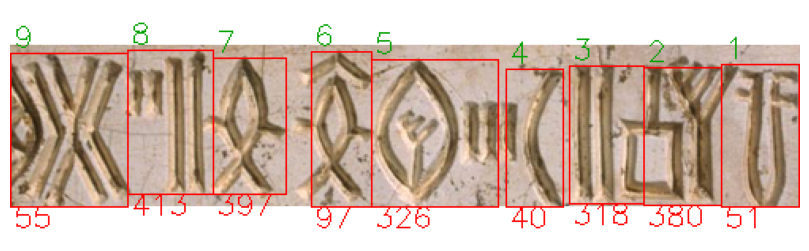

In [2]:
image = load_image(PHOTO)
readings = read_text_row(image)          # this photo is already just the text row

print("sequence (reading order):", " ".join(str(r.best) for r in readings))

# OpenCV stores colour as BGR, matplotlib expects RGB, so convert before showing
shown = cv2.cvtColor(draw_readings(image, readings), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 3))
plt.imshow(shown)
plt.axis("off")
plt.show()

Green numbers: reading position (1 = read first, at the right). Red numbers under each box: the best-guess Mahadevan ID.

## 2. Each sign next to its top-5 templates

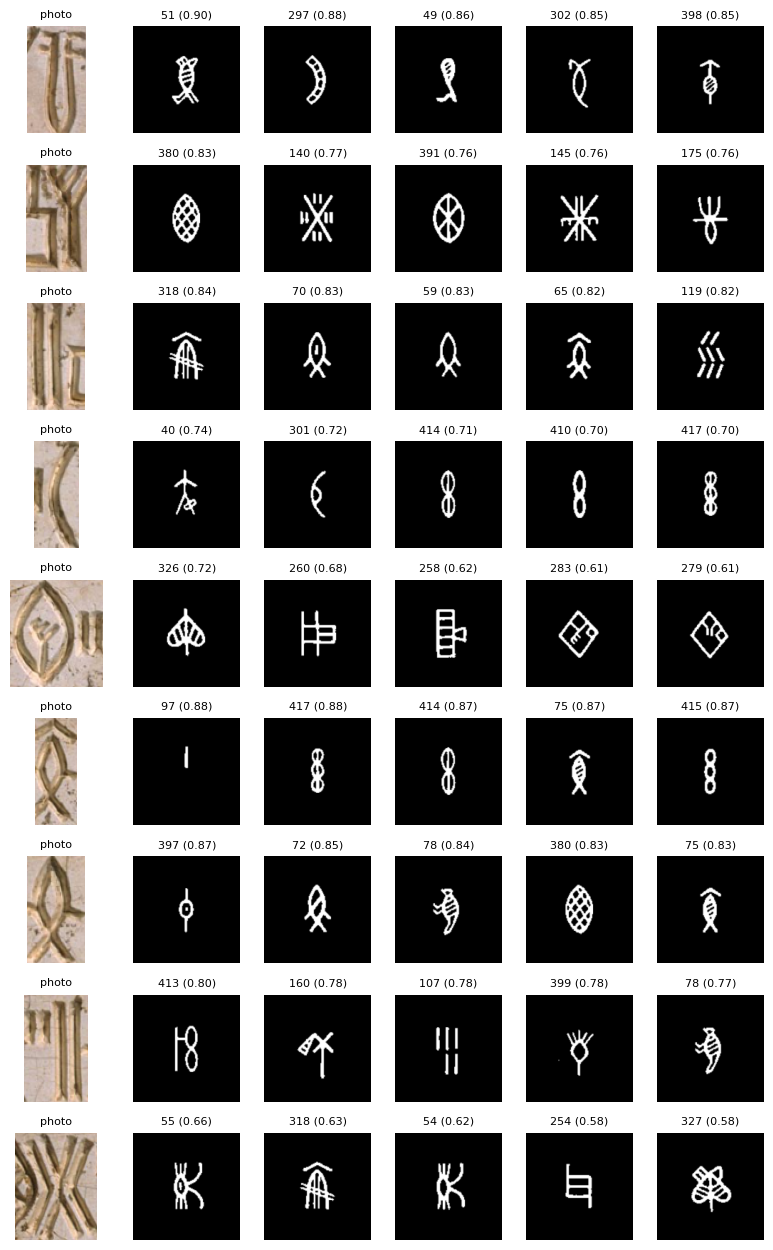

In [3]:
fig, axes = plt.subplots(len(readings), 6, figsize=(8, 1.4 * len(readings)))
for row, r in zip(axes, readings):
    row[0].imshow(cv2.cvtColor(r.box.crop(image), cv2.COLOR_BGR2RGB))
    row[0].set_title("photo", fontsize=8)
    for ax, m in zip(row[1:], r.matches):
        ax.imshow(cv2.imread(str(template_path(m.mahadevan_id)), cv2.IMREAD_GRAYSCALE), cmap="gray")
        ax.set_title(f"{m.mahadevan_id} ({m.score:.2f})", fontsize=8)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.show()

Scores are correlations (1 = identical shape). They are **not** a confidence: wrong guesses often score about 0.9. Accuracy on real photos needs P3's ground truth (A4).